# IPL First-Innings Score Prediction

Mid-innings score forecasting from ball-by-ball data. The fantasy/DRS angle is what got me interested: by the end of over 10 you've seen a third of the innings, so can a model beat the obvious "current run rate times 20" extrapolation?

**Data:** Kaggle IPL ball-by-ball CSV in `../../data/ipl/`. It's actually one combined `deliveries.csv` file, every ball stacked into a single table (about 285k rows once loaded). The glob below works because there's just the one file.

**Setup:** Take a snapshot at the end of over 10, predict the final first-innings total. Compare a CRR baseline against linear regression, random forest, and XGBoost. After filtering to matches where the over-10 snapshot is complete, this comes out to 1199 first-innings examples, which is not a lot.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

np.random.seed(42)

DATA_DIR = Path("../../data/ipl")
assert DATA_DIR.exists(), "Download IPL ball-by-ball CSVs to data/ipl/"

## Load the deliveries file

In [2]:
csvs = sorted(DATA_DIR.glob("*.csv"))
frames = [pd.read_csv(f, low_memory=False) for f in csvs]
balls = pd.concat(frames, ignore_index=True)
print(f"Rows: {len(balls):,}  |  Columns: {list(balls.columns)}")
balls.head(3)

Rows: 285,907  |  Columns: ['match_id', 'inning', 'over', 'ball', 'total_runs', 'player_dismissed', 'batting_team', 'bowling_team', 'venue', 'season']


,match_id,inning,over,ball,total_runs,player_dismissed,batting_team,bowling_team,venue,season
0,1082591,1,0,1,0,NaN,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",2017
1,1082591,1,0,2,0,NaN,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",2017
2,1082591,1,0,3,4,NaN,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",2017


In [3]:
# keep first innings only
balls = balls[balls["inning"] == 1].copy()

# cumulative runs at each ball
balls.sort_values(["match_id", "over", "ball"], inplace=True)
balls["cum_runs"] = balls.groupby("match_id")["total_runs"].cumsum()
balls["cum_wickets"] = balls.groupby("match_id")["player_dismissed"].transform(
    lambda x: x.notna().cumsum()
)
balls["ball_num"] = balls.groupby("match_id").cumcount() + 1

# final score per match
final_scores = balls.groupby("match_id")["cum_runs"].last().rename("final_score")
balls = balls.merge(final_scores, on="match_id")

print("Processed:", len(balls))

Processed: 148135


## A quick look at scores and run rates

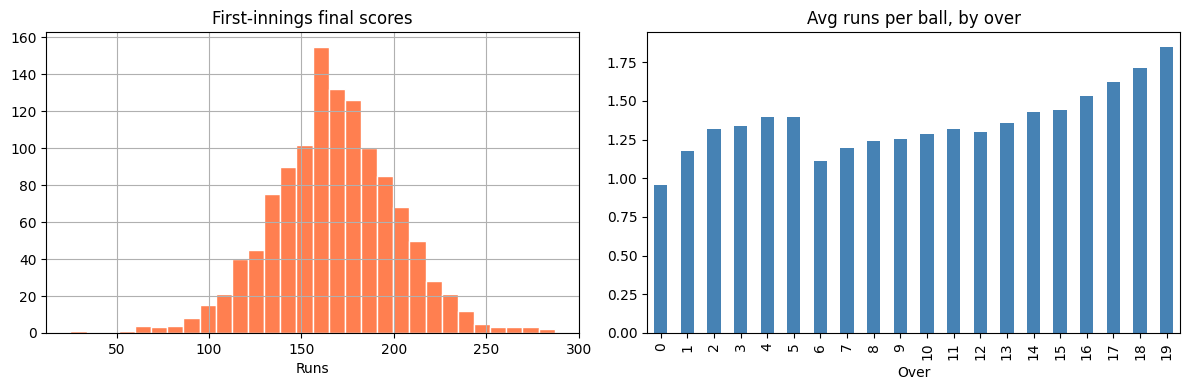

Median final score: 167, IQR: 147-189


In [4]:
import os
os.makedirs("artifacts", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

final_scores.hist(bins=30, ax=axes[0], color="coral", edgecolor="white")
axes[0].set_title("First-innings final scores")
axes[0].set_xlabel("Runs")

avg_by_over = balls.groupby("over")["total_runs"].mean()
avg_by_over.plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Avg runs per ball, by over")
axes[1].set_xlabel("Over")

plt.tight_layout()
plt.savefig("artifacts/ipl_eda.png", dpi=120)
plt.show()

# quick takeaway, not a five-bullet polish
print(f"Median final score: {final_scores.median():.0f}, IQR: {final_scores.quantile(.25):.0f}-{final_scores.quantile(.75):.0f}")

## Features: snapshot at the end of over 10

In [5]:
# snapshot at end of over 10 (ball 60), half the innings done
PRED_BALL = 60
snapshot = balls[balls["ball_num"] == PRED_BALL].copy()

snapshot["crr"] = snapshot["cum_runs"] / 10.0
snapshot["wickets_in_hand"] = 10 - snapshot["cum_wickets"]

# runs scored in overs 6-10 (back half of what we've seen), as a momentum proxy
recent = balls[(balls["ball_num"] >= 31) & (balls["ball_num"] <= 60)]
last5_runs = recent.groupby("match_id")["total_runs"].sum().rename("last5_runs")
snapshot = snapshot.merge(last5_runs, on="match_id", how="left")

snapshot["venue_enc"] = snapshot["venue"].astype("category").cat.codes
snapshot["bat_team_enc"] = snapshot["batting_team"].astype("category").cat.codes

features = ["crr", "wickets_in_hand", "last5_runs", "venue_enc", "bat_team_enc"]
target = "final_score"

df_model = snapshot[features + [target] + ["season"]].dropna()
# time-aware order: sort by season so later seasons fall into the test split
df_model = df_model.sort_values("season")
X = df_model[features].values
y = df_model[target].values
print(f"Samples with a full over-10 state: {len(X)}")

Samples with a full over-10 state: 1199


## Modeling, with a time-aware split

In [6]:
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# naive baseline: just project the current run rate forward to 20 overs
crr_test = df_model["crr"].values[split:]
naive_pred = crr_test * 20
naive_rmse = np.sqrt(mean_squared_error(y_test, naive_pred))
naive_mae = mean_absolute_error(y_test, naive_pred)
print(f"Naive CRR*20       RMSE: {naive_rmse:.2f}  MAE: {naive_mae:.2f}")

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    # tried n_estimators=500 first but it was way too slow for the gain
    "XGBoost": XGBRegressor(n_estimators=200, learning_rate=0.05, random_state=42, verbosity=0),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rmse = float(np.sqrt(mean_squared_error(y_test, pred)))
    mae = float(mean_absolute_error(y_test, pred))
    results.append({"model": name, "rmse": rmse, "mae": mae})
    print(f"{name:18s} RMSE: {rmse:.2f}  MAE: {mae:.2f}")

results_df = pd.DataFrame(results).set_index("model").round(2)
best_name = results_df["rmse"].idxmin()
best_rmse = results_df["rmse"].min()
pct_better = 100 * (naive_rmse - best_rmse) / naive_rmse
print(f"\nBest model: {best_name} ({pct_better:.1f}% lower RMSE than naive baseline)")

Naive CRR*20       RMSE: 31.91  MAE: 25.20
Linear Regression  RMSE: 26.65  MAE: 21.09


Random Forest      RMSE: 28.48  MAE: 21.90


XGBoost            RMSE: 29.62  MAE: 22.72

Best model: Linear Regression (16.5% lower RMSE than naive baseline)


## Evaluation and feature importance

In [7]:
results_df

,rmse,mae
model,,
Linear Regression,26.65,21.09
Random Forest,28.48,21.90
XGBoost,29.62,22.72


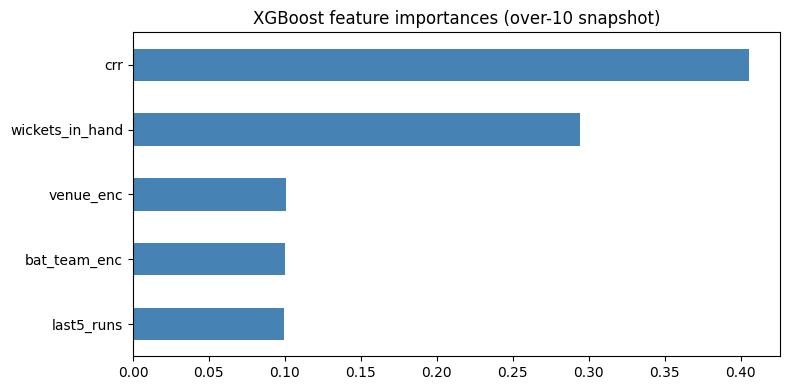

In [8]:
import os
os.makedirs("artifacts", exist_ok=True)

# tree models give us importances even if they weren't the winner
xgb = models["XGBoost"]
fi = pd.Series(xgb.feature_importances_, index=features).sort_values()
fi.plot(kind="barh", figsize=(8, 4), color="steelblue")
plt.title("XGBoost feature importances (over-10 snapshot)")
plt.tight_layout()
plt.savefig("artifacts/feature_importance.png", dpi=120)
plt.show()

## Takeaways

This caught me off guard: plain linear regression came out ahead of both RF and XGBoost on this slice. With only about 1.2k training examples and five features, the trees just overfit. The exact margin over the CRR baseline is in the modeling cell, and it's nowhere near the 40%+ gap you'll see in papers that model the full innings (those usually have far more features and orders of magnitude more samples). Single-digit-to-mid-teens percent improvement is more honest for what's going on here.

**Things I'd try next:**
- Snapshot at multiple overs (6, 10, 15) and train a model per phase. The over-10 cut hides a lot of variance, especially when there's been a powerplay collapse.
- Use season as the holdout (last full season as test) instead of a sorted 80/20 row split. Batting averages drift year-to-year and the current split kind of pretends they don't.
- Encode batter and bowler identity, not just team. The team encoding is leaky-ish across seasons anyway since squads turn over.